In [ ]:
# script for downloading NASA GEX-NDDP data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import os
import warnings
warnings.filterwarnings('ignore')
from urllib.parse import urlencode, urljoin
from urllib.request import urlopen

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt
import xarray as xr

## Change path to correct data directory

In [2]:
! pwd

/Users/tedscott/Google Drive/My Drive/PhD Work/Codes/HeatWaves/HeatWaves


In [8]:
# example URL: https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/CESM2/historical/r4i1p1f1/tas/tas_day_CESM2_historical_r4i1p1f1_gn_1962_v2.0.nc
#os.chdir('../../../Data/CMIP6/NEX-GDDP-CMIP6/CMCC-ESM2/raw')
! ls -al

total 66606520
drwxr-xr-x@ 143 tedscott  staff       4576 Oct 13 11:45 .
drwxr-xr-x@   5 tedscott  staff        160 Oct 13 00:25 ..
-rw-r--r--@   1 tedscott  staff       6148 Oct 12 15:34 .DS_Store
-rw-r--r--@   1 tedscott  staff  243142761 Oct 11 22:00 tas_day_CMCC-ESM2_historical_r1i1p1f1_gn_1961_v2.0.nc
-rw-r--r--@   1 tedscott  staff  243206341 Oct 11 22:10 tas_day_CMCC-ESM2_historical_r1i1p1f1_gn_1962_v2.0.nc
-rw-r--r--@   1 tedscott  staff  243212784 Oct 11 22:19 tas_day_CMCC-ESM2_historical_r1i1p1f1_gn_1963_v2.0.nc
-rw-r--r--@   1 tedscott  staff  243095697 Oct 11 22:32 tas_day_CMCC-ESM2_historical_r1i1p1f1_gn_1964_v2.0.nc
-rw-r--r--@   1 tedscott  staff  243143902 Oct 11 22:41 tas_day_CMCC-ESM2_historical_r1i1p1f1_gn_1965_v2.0.nc
-rw-r--r--@   1 tedscott  staff  243122566 Oct 11 22:53 tas_day_CMCC-ESM2_historical_r1i1p1f1_gn_1966_v2.0.nc
-rw-r--r--@   1 tedscott  staff  243082083 Oct 11 23:03 tas_day_CMCC-ESM2_historical_r1i1p1f1_gn_1967_v2.0.nc
-rw-r--r--@   1 tedscott  staff 

## Download files

In [7]:
# try downloading to local drive to see if this is faster?
#os.chdir('/Users/tedscott/Downloads/CMIP6-downloads/')

In [6]:
process_yrs = np.arange(2075,2101,1)
#process_yrs = [2016]
process_yrs

array([2075, 2076, 2077, 2078, 2079, 2080, 2081, 2082, 2083, 2084, 2085,
       2086, 2087, 2088, 2089, 2090, 2091, 2092, 2093, 2094, 2095, 2096,
       2097, 2098, 2099, 2100])

In [7]:
%%time
# taking roughly 9 min per file on 2026-10-06
# help from https://realpython.com/python-download-file-from-url/#downloading-a-large-file-in-a-streaming-fashion

scenario = "ssp245"#"historical"#"ssp245"
realization = "r1i1p1f1"#"r4i1p1f1"
model = "CMCC-ESM2"#"CanESM5"#"CESM2"
grid = "gn"#"gr1"#"gn"

for yr in process_yrs:

    start = dt.now()
    
    filename = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    url = "https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/"+model+"/"+scenario+"/"+realization+"/tas/"+filename
    response = requests.get(url, stream=True)
    response.headers

    with open(filename, mode="wb") as file:
        for chunk in response.iter_content():
            file.write(chunk)
            
    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")


Time for 2075 :8.900732533333333 min
Time for 2076 :8.979421883333334 min
Time for 2077 :9.015278283333334 min
Time for 2078 :8.98967815 min
Time for 2079 :8.990401183333335 min
Time for 2080 :8.980963733333335 min
Time for 2081 :9.068654949999999 min
Time for 2082 :9.056098783333335 min
Time for 2083 :8.9753895 min
Time for 2084 :8.990080433333333 min
Time for 2085 :9.067719533333333 min
Time for 2086 :9.0114361 min
Time for 2087 :9.066921683333334 min
Time for 2088 :9.088667033333333 min
Time for 2089 :9.037007766666667 min
Time for 2090 :9.097164716666667 min
Time for 2091 :9.025092366666666 min
Time for 2092 :9.047713483333332 min
Time for 2093 :9.095220633333334 min
Time for 2094 :9.024774533333334 min
Time for 2095 :9.040596083333332 min
Time for 2096 :9.039542183333333 min
Time for 2097 :9.0970648 min
Time for 2098 :9.0700766 min
Time for 2099 :9.03282015 min
Time for 2100 :9.009362133333333 min
CPU times: user 3h 52min 28s, sys: 59.8 s, total: 3h 53min 28s
Wall time: 3h 54min 4

## Use CDO to regrid to match ERA5 and fix time variable

### using os.system() calls to cdo

In [23]:
process_yrs = np.arange(1961,2015,1)
scenario = "historical"

In [ ]:
%%time

for yr in process_yrs:
    start = dt.now()

    # change grid to match ERA5
    cmd = "remapbil,r1440x721"
    infile = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    os.system("cdo "+cmd+" "+infile+" "+outfile)

    # set longitude range
    cmd2 = "-sellonlatbox,-180,180,-90,90"
    infile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+str(yr)+"_1440x721.nc"
    os.system("cdo "+cmd2+" "+infile2+" "+outfile2)

    # fix time variable
    ds_model = xr.open_mfdataset(outfile2)
    ds_model['time'] = ds_model.indexes['time'].to_datetimeindex() # ACCESS-ESM1-5 is already datetime64?

    # output final version
    outpath = "../regridded/tas_"+model+"_"+scenario+"_"+str(yr)+".nc"

    # include some compression to reduce file size on disk
    comp = dict(zlib=True, complevel=5)
    encoding = {var: comp for var in ds_model.data_vars}
    ds_model.to_netcdf(outpath, encoding=encoding)
    
    # remove intermediate files
    os.system("rm "+outfile)
    os.system("rm "+outfile2)

    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")

cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2075 :12.20987015 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2076 :12.153726633333333 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


...

cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2093 :12.109567449999998 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2094 :11.985512566666667 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)


In [25]:
ds_model

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 365, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2014-01-01T12:00:00 ... 2014-12-31T12:...
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    tas      (time, lat, lon) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
Attributes: (12/24)
    CDI:                   Climate Data Interface version 2.5.0 (https://mpim...
    Conventions:           CF-1.7
    source:                BCSD
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    activity:              NEX-GDDP-CMIP6
    frequency:             day
    ...                    ...
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sat Nov 16 20:03:35 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           b3dc8e7a-5228-4c0d-b08b-ba58f56cfd6b
    history:               Sun Oct 11 21:14:49 2026: cdo -sellonlatbox,-180,1...
    CDO:                   Climate Data Operators version 2.5.0 (https://mpim...

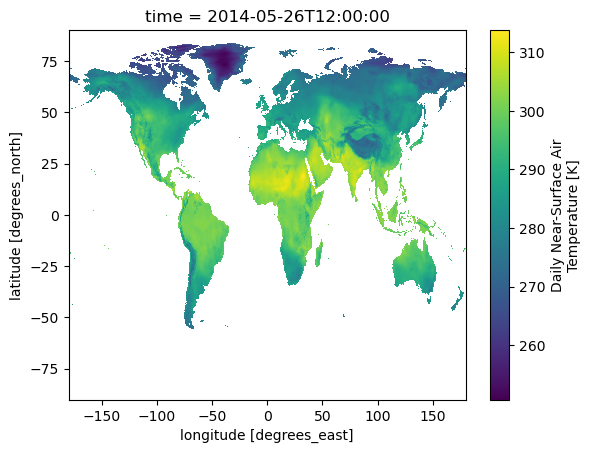

In [26]:
ds_model.tas.sel(time="2014-05-26").plot()